# Introduction: Leveraging Data Science to Analyze Loan Data

In the realm of finance, making informed decisions regarding loans is paramount to mitigating risks and ensuring optimal portfolio management. As such, data science techniques offer a robust framework for extracting insights from vast datasets to inform these decisions. This project focuses on analyzing a dataset sourced from LendingClub.com, comprising various attributes related to loans. The objective is to utilize data science methodologies to gain a comprehensive understanding of the factors influencing loan performance and borrower behavior.

## Problem Statement

The dataset encompasses diverse features such as credit policies, interest rates, borrower income levels, debt-to-income ratios, and credit scores, among others. The primary objective is to predict whether a borrower will fully repay the loan or not, categorized under the 'not.fully.paid' column. This classification task serves as the crux of the analysis, aiming to develop a predictive model that accurately discerns borrowers who are likely to default on their loans.

## Methodology

To systematically approach this problem, we adopt the CRISP-DM methodology, a well-established framework for guiding data mining and analytics projects. The CRISP-DM process comprises six key phases:

1. **Business Understanding:** This initial phase involves understanding the business objectives and defining the problem statement. In our case, it entails grasping the significance of loan performance prediction for financial institutions and identifying the key metrics for evaluation.

2. **Data Understanding (EDA):** Here, we explore the dataset to gain insights into its structure, content, and quality. We examine the features, their distributions, missing values, and potential correlations to inform subsequent steps.

3. **Data Preparation:** In this phase, we preprocess the data to ensure its suitability for analysis. Tasks include handling missing values, encoding categorical variables, scaling numerical features, and possibly feature engineering to enhance model performance.

4. **Modeling:** With the prepared data, we proceed to build predictive models using machine learning algorithms. We employ techniques such as logistic regression, decision trees, random forests, and gradient boosting to train and evaluate models for loan repayment prediction.

5. **Evaluation:** In this phase, we assess the performance of the trained models using appropriate evaluation metrics such as accuracy, precision, recall, and area under the ROC curve (AUC). We iteratively fine-tune the models to optimize their predictive capabilities.

6. **Deployment:** Upon selecting the best-performing model, we deploy it for practical use, enabling stakeholders to make informed decisions based on real-time loan predictions. Additionally, we document the entire process and findings for future reference and continuous improvement.

# 2. Data Understanding (EDA)  

### About Dataset  
    
The publicly available data is from LendingClub.com and covers the years 2007 to 2010. Lending Club connects people who need money (borrowers) with people who have money (investors).

#### Here are what the columns represent:
1. **credit.policy:** 1 if the customer meets the credit underwriting criteria of LendingClub.com, and 0 otherwise.

2. **purpose:** The purpose of the loan (takes values "credit_card", "debt_consolidation", "educational", "major_purchase", "small_business", and "all_other").

3. **int.rate:** The interest rate of the loan, as a proportion (a rate of 11% would be stored as 0.11). Borrowers judged by LendingClub.com to be more risky are assigned higher interest rates.

4. **installment:** The monthly installments owed by the borrower if the loan is funded.

5. **log.annual.inc:** The natural log of the self-reported annual income of the borrower.

6. **dti:** The debt-to-income ratio of the borrower (amount of debt divided by annual income).

7. **fico:** The FICO credit score of the borrower.

8. **days.with.cr.line:** The number of days the borrower has had a credit line.

9. **revol.bal:** The borrower's revolving balance (amount unpaid at the end of the credit card billing cycle).

10. **revol.util:** The borrower's revolving line utilization rate (the amount of the credit line used relative to total credit available).

11. **inq.last.6mths:** The borrower's number of inquiries by creditors in the last 6 months.

12. **delinq.2yrs:** The number of times the borrower had been 30+ days past due on a payment in the past 2 years.

13. **pub.rec:** The borrower's number of derogatory public records (bankruptcy filings, tax liens, or judgments).

14. **not.fully.paid:** It is our Target.

### Loading Dataset into DataFrame

We started by loading the dataset into a DataFrame and conducting initial data exploration tasks to gain a better understanding of the data structure and classification columns.


#### Next Steps

1. **Data Cleaning**: We performed data cleaning tasks such as handling missing values, removing duplicates, and addressing data inconsistencies to prepare the dataset for analysis.
2. **Exploratory Data Analysis (EDA)**: We conducted exploratory data analysis to gain insights into the dataset's characteristics, relationships between variables, and potential patterns or trends.
3. **Feature Engineering**: We performed feature engineering to create new features, transform existing features, or select relevant features to improve model performance and interpretability.

In summary, conducting initial data exploration tasks are essential steps in any data analysis or modeling project, providing a foundation for subsequent analysis and decision-making processes.

In [30]:
# First, you need to install pandas if you haven't already. You can do this via pip:
# !pip install pandas

# Now, let's import the pandas library
import pandas as pd

# Replace 'file_path.csv' with the actual path to your CSV file
file_path = '/kaggle/input/loan-data/loan_data.csv'

# Now, let's read the CSV file into a DataFrame using pandas
# The read_csv() function is used for reading the data
# We'll store the data in a variable called 'df' (short for DataFrame)
df = pd.read_csv(file_path)

In [31]:
df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [32]:
# Display basic information about the dataset
print("\nDataset Info:")
print(df.info())

# Unique Values in Categorical Columns
print("\nNumber of Unique Values in Categorical Columns:")
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    print(col, ": ", df[col].nunique())
    
# Distribution of categorical variable 'purpose'
print("\nDistribution of 'purpose' variable:")
print(df['purpose'].value_counts())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   object 
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 1.0+ MB
None

Number of Unique Values in Categorical Col

### Statistical Summary for Numerical Columns

In this phase of the project, we generated a statistical summary for the numerical columns in the dataset. A statistical summary provides key descriptive statistics that summarize the central tendency, dispersion, and shape of the data distribution, offering valuable insights into the dataset's characteristics.

In [33]:
import seaborn as sns

# Compute summary statistics for numerical columns
numerical_summary = df.describe().transpose()

# Define color palette
palette = sns.color_palette("viridis", as_cmap=True)

# Define a function to apply background gradient
def apply_gradient(s):
    return [f'background-color: {palette(s)}' for s in s]

# Apply background gradient using Styler.apply()
styled_summary = numerical_summary.style.apply(apply_gradient)

# Display the styled summary statistics
styled_summary

,count,mean,std,min,25%,50%,75%,max
credit.policy,9578.000000,0.804970,0.396245,0.000000,1.000000,1.000000,1.000000,1.000000
int.rate,9578.000000,0.122640,0.026847,0.060000,0.103900,0.122100,0.140700,0.216400
installment,9578.000000,319.089413,207.071301,15.670000,163.770000,268.950000,432.762500,940.140000
log.annual.inc,9578.000000,10.932117,0.614813,7.547502,10.558414,10.928884,11.291293,14.528354
dti,9578.000000,12.606679,6.883970,0.000000,7.212500,12.665000,17.950000,29.960000
fico,9578.000000,710.846314,37.970537,612.000000,682.000000,707.000000,737.000000,827.000000
days.with.cr.line,9578.000000,4560.767197,2496.930377,178.958333,2820.000000,4139.958333,5730.000000,17639.958330
revol.bal,9578.000000,16913.963876,33756.189557,0.000000,3187.000000,8596.000000,18249.500000,1207359.000000
revol.util,9578.000000,46.799236,29.014417,0.000000,22.600000,46.300000,70.900000,119.000000
inq.last.6mths,9578.000000,1.577469,2.200245,0.000000,0.000000,1.000000,2.000000,33.000000


### Class Distribution Analysis

We conducted an analysis of the class distribution for the target variable ('not.fully.paid') as well as for the 'credit.policy' and 'purpose' features in the dataset. Class distribution analysis provides insights into the distribution of different classes within categorical variables, aiding in understanding the balance and imbalance of classes.

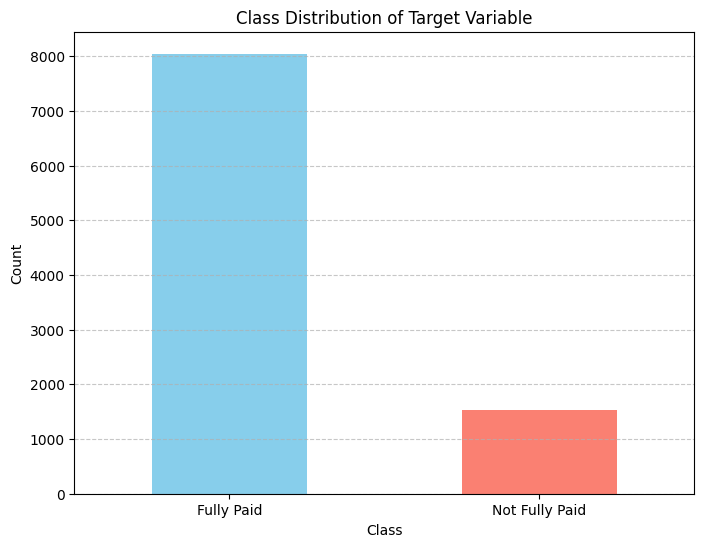

In [34]:
import matplotlib.pyplot as plt

# Class distribution of the target variable
class_distribution = df['not.fully.paid'].value_counts()

# Plotting the class distribution
plt.figure(figsize=(8, 6))
class_distribution.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Class Distribution of Target Variable')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks([0, 1], ['Fully Paid', 'Not Fully Paid'], rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

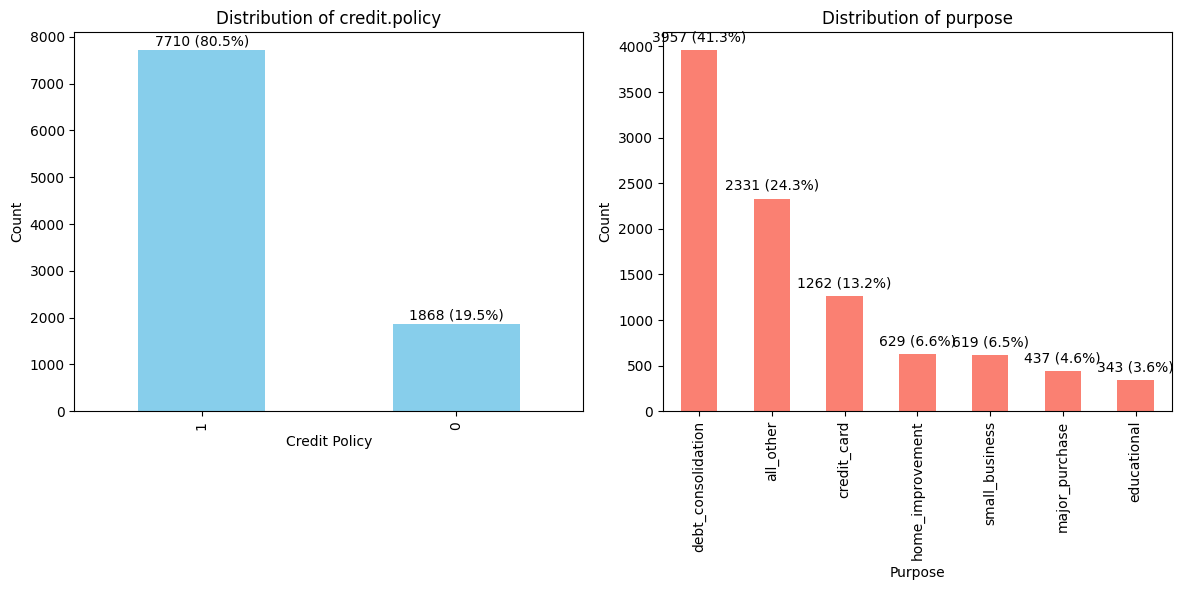

In [35]:
import matplotlib.pyplot as plt

# Set figure size
plt.figure(figsize=(12, 6))

# Plot bar chart for distribution of 'credit.policy'
plt.subplot(1, 2, 1)
df['credit.policy'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Distribution of credit.policy')
plt.xlabel('Credit Policy')
plt.ylabel('Count')

# Add percentage labels on top of each bar
total_credit_policy = len(df['credit.policy'])
for i, count in enumerate(df['credit.policy'].value_counts()):
    plt.text(i, count + total_credit_policy * 0.01, f'{count} ({count / total_credit_policy:.1%})', ha='center')

# Plot bar chart for distribution of 'purpose'
plt.subplot(1, 2, 2)
df['purpose'].value_counts().plot(kind='bar', color='salmon')
plt.title('Distribution of purpose')
plt.xlabel('Purpose')
plt.ylabel('Count')

# Add percentage labels on top of each bar
total_purpose = len(df['purpose'])
for i, count in enumerate(df['purpose'].value_counts()):
    plt.text(i, count + total_purpose * 0.01, f'{count} ({count / total_purpose:.1%})', ha='center')

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()

# 3. Data Preparation

### Conversion of Features to Boolean Type

In this phase of the project, we converted the 'credit.policy' and 'not.fully.paid' features to boolean type in the dataset. Converting features to boolean type is a common preprocessing step in data analysis and machine learning tasks, particularly when dealing with binary categorical variables.  
  
#### Purpose of Conversion

- **Boolean Representation**: Converting features to boolean type represents binary categorical variables as True or False values, making them suitable for binary classification tasks.
- **Simplification**: Boolean representation simplifies the interpretation and manipulation of binary categorical variables, enhancing the efficiency of data analysis and modeling.
- **Alignment with Analysis Needs**: Converting features to boolean type aligns the data representation with the requirements of subsequent analysis and modeling steps, ensuring consistency and compatibility.

In [36]:
# Convert 'credit.policy' feature to boolean type
df['credit.policy'] = df['credit.policy'].astype(bool)

# Convert 'not.fully.paid' feature to boolean type
df['not.fully.paid'] = df['not.fully.paid'].astype(bool)

# Display the first few rows of the dataset to verify the changes
df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,True,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,False
1,True,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,False
2,True,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,False
3,True,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,False
4,True,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,False


### Sorting Unique Values

We sorted the unique values for the features 'inq.last.6mths', 'delinq.2yrs', and 'pub.rec' in the dataset. Sorting unique values is a useful preprocessing step that provides insights into the range and distribution of values within categorical variables.

In [37]:
# Features of interest
features_of_interest = ['inq.last.6mths', 'delinq.2yrs', 'pub.rec']

# Dictionary to store unique values and their percentages
unique_values_with_percentage = {}

# Calculate unique values and their percentages for each feature
for feature in features_of_interest:
    # Calculate unique values and their counts
    unique_values_count = df[feature].value_counts().sort_index()
    # Calculate percentages for each value
    percentages = (unique_values_count / df.shape[0]) * 100
    # Store unique values and their percentages in the dictionary
    unique_values_with_percentage[feature] = {'unique_values': unique_values_count.index.tolist(),
                                              'percentages': percentages.tolist()}

# Print the sorted unique values and their percentages for each feature
for feature, values_percentage in unique_values_with_percentage.items():
    print(f"Feature: {feature}")
    print("Unique Values: ", values_percentage['unique_values'])
    print("Percentages: ", values_percentage['percentages'])
    print()

Feature: inq.last.6mths
Unique Values:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 24, 25, 27, 28, 31, 32, 33]
Percentages:  [37.97243683441219, 25.70474002923366, 14.449780747546463, 9.020672374190854, 4.959281687199833, 2.902484861140113, 1.7226978492378369, 1.044059302568386, 0.7517226978492378, 0.49070787220714135, 0.24013363959072875, 0.15660889538525788, 0.15660889538525788, 0.06264355815410315, 0.06264355815410315, 0.09396533723115473, 0.031321779077051574, 0.02088118605136772, 0.04176237210273544, 0.02088118605136772, 0.01044059302568386, 0.02088118605136772, 0.01044059302568386, 0.01044059302568386, 0.01044059302568386, 0.01044059302568386, 0.01044059302568386, 0.01044059302568386]

Feature: delinq.2yrs
Unique Values:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 11, 13]
Percentages:  [88.30653581123407, 8.68657339736897, 2.0045938609313008, 0.6786385466694509, 0.1983712674879933, 0.06264355815410315, 0.02088118605136772, 0.01044059302568386, 0.01044059302568386

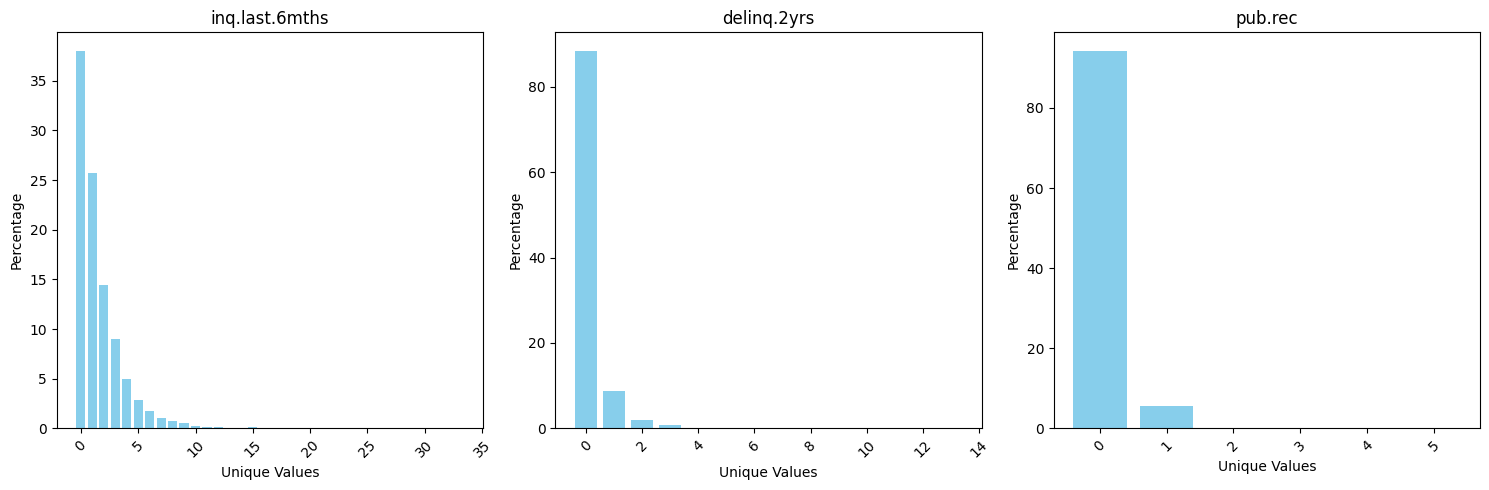

In [38]:
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(15, 5))

# Iterate over each feature
for i, (feature, values_percentage) in enumerate(unique_values_with_percentage.items(), start=1):
    # Create subplot
    plt.subplot(1, len(features_of_interest), i)
    
    # Plot bar chart
    plt.bar(values_percentage['unique_values'], values_percentage['percentages'], color='skyblue')
    
    # Set title and labels
    plt.title(feature)
    plt.xlabel('Unique Values')
    plt.ylabel('Percentage')
    
    # Rotate x-axis labels if too crowded
    if len(values_percentage['unique_values']) > 5:
        plt.xticks(rotation=45)
    
# Adjust layout
plt.tight_layout()

# Show plot
plt.show()

### Custom Binning Method
In this phase of the project, we implemented a custom binning method for these features in the dataset. Custom binning involves categorizing continuous or discrete numerical variables into predefined bins or intervals based on specific criteria or thresholds.

#### Benefits of Custom Binning

- **Feature Engineering**: Custom binning enhances feature engineering efforts by capturing meaningful patterns or relationships within numerical variables, leading to improved model performance.
- **Interpretability**: Binned features are more interpretable than continuous variables, as they represent discrete categories or intervals that are easier to understand and communicate.
- **Model Performance**: Binning can improve model performance by reducing noise, handling outliers, and capturing nonlinear relationships between variables.

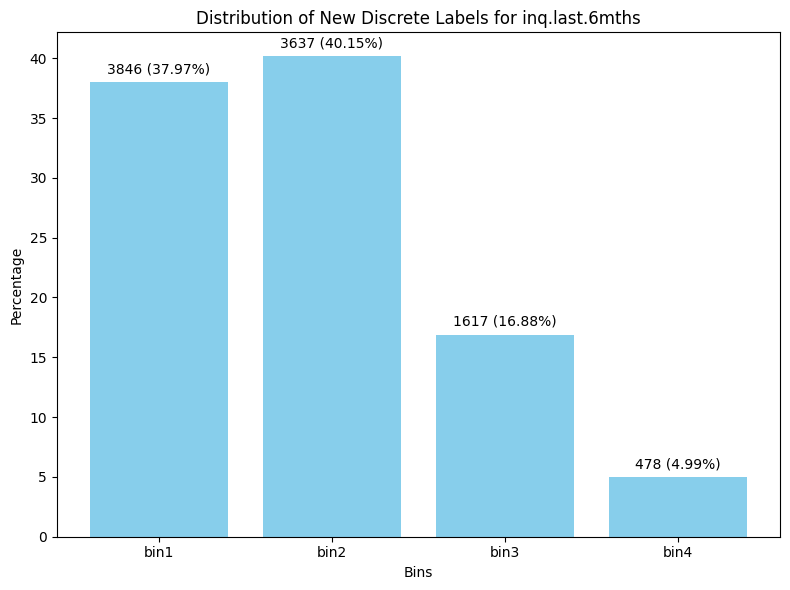

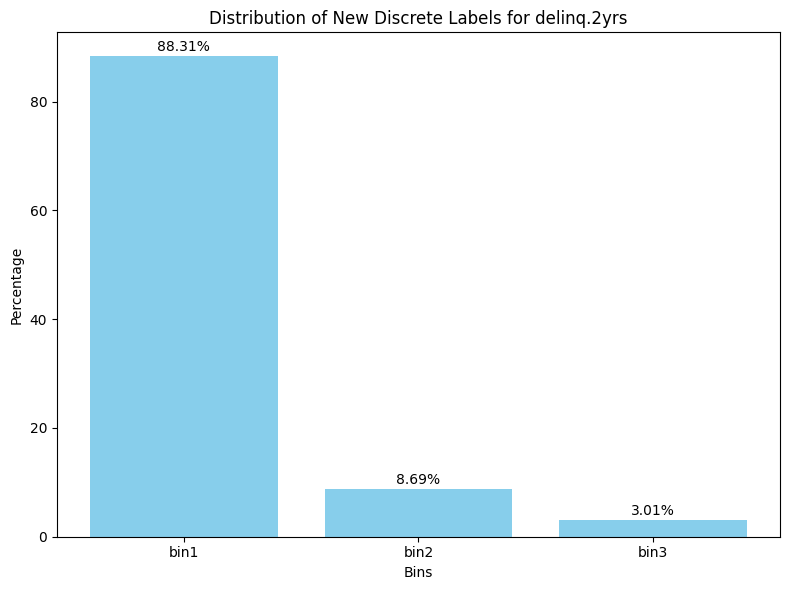

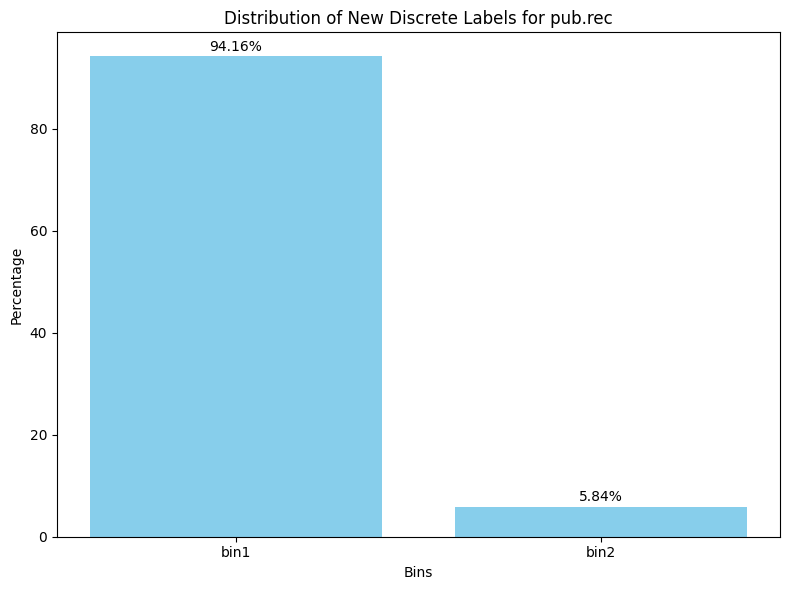

In [39]:
import matplotlib.pyplot as plt

# Define custom binning function
def custom_binning(value):
    if value == 0:
        return 'bin1'
    elif value in [1, 2]:
        return 'bin2'
    elif value in [3, 4, 5]:
        return 'bin3'
    else:
        return 'bin4'

# Apply custom binning function to 'inq.last.6mths' feature
df['inq_bin'] = df['inq.last.6mths'].apply(custom_binning)

# Calculate distribution of new discrete labels
inq_bin_distribution = df['inq_bin'].value_counts(normalize=True) * 100

# Sort the bins by their names
inq_bin_distribution_sorted = inq_bin_distribution.sort_index()

# Create a bar plot
plt.figure(figsize=(8, 6))
bars = plt.bar(inq_bin_distribution_sorted.index, inq_bin_distribution_sorted.values, color='skyblue')

# Add counts and percentages as text on top of each bar
for bar, count, percentage in zip(bars, df['inq_bin'].value_counts(), inq_bin_distribution_sorted):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f"{count} ({percentage:.2f}%)",
             ha='center', va='bottom', fontsize=10)

# Set title and labels
plt.title('Distribution of New Discrete Labels for inq.last.6mths')
plt.xlabel('Bins')
plt.ylabel('Percentage')

# Show plot
plt.tight_layout()
plt.show()

# Define custom binning function for 'delinq.2yrs' feature
def custom_binning_delinq(value):
    if value == 0:
        return 'bin1'
    elif value == 1:
        return 'bin2'
    else:
        return 'bin3'

# Apply custom binning function to 'delinq.2yrs' feature
df['delinq_bin'] = df['delinq.2yrs'].apply(custom_binning_delinq)

# Calculate distribution of new discrete labels
delinq_bin_distribution = df['delinq_bin'].value_counts(normalize=True) * 100

# Create a bar plot
plt.figure(figsize=(8, 6))
bars = plt.bar(delinq_bin_distribution.index, delinq_bin_distribution.values, color='skyblue')

# Add percentages as text on top of each bar
for bar, percentage in zip(bars, delinq_bin_distribution):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f"{percentage:.2f}%",
             ha='center', va='bottom', fontsize=10)

# Set title and labels
plt.title('Distribution of New Discrete Labels for delinq.2yrs')
plt.xlabel('Bins')
plt.ylabel('Percentage')

# Show plot
plt.tight_layout()
plt.show()

# Define custom binning function for 'pub.rec' feature
def custom_binning_pubrec(value):
    if value == 0:
        return 'bin1'
    else:
        return 'bin2'

# Apply custom binning function to 'pub.rec' feature
df['pubrec_bin'] = df['pub.rec'].apply(custom_binning_pubrec)

# Calculate distribution of new discrete labels
pubrec_bin_distribution = df['pubrec_bin'].value_counts(normalize=True) * 100

# Create a bar plot
plt.figure(figsize=(8, 6))
bars = plt.bar(pubrec_bin_distribution.index, pubrec_bin_distribution.values, color='skyblue')

# Add percentages as text on top of each bar
for bar, percentage in zip(bars, pubrec_bin_distribution):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f"{percentage:.2f}%",
             ha='center', va='bottom', fontsize=10)

# Set title and labels
plt.title('Distribution of New Discrete Labels for pub.rec')
plt.xlabel('Bins')
plt.ylabel('Percentage')

# Show plot
plt.tight_layout()
plt.show()

### Identification of Records with Values Over 100% in 'revol.util' Feature

We identified records with values over 100% in the 'revol.util' feature of the dataset. Then we filtered the records and updated the values to 100%.
  
  The 'revol.util' feature represents the borrower's revolving line utilization rate, which indicates the percentage of the credit line used relative to the total credit available. Values over 100% in this feature may indicate data errors or inconsistencies that require investigation.

In [40]:
# Filter records where 'revol.util' is greater than 100%
over_100_util_records = df[df['revol.util'] > 100]

# Add row numbers to the DataFrame after resetting the index
over_100_util_records.insert(0, 'Row Number', over_100_util_records.index + 1)

# Reset the index to remove the default index and avoid duplicates
over_100_util_records.reset_index(drop=True, inplace=True)

# Define a function to apply purple color to 'revol.util'
def highlight_revol_util(column):
    if column.name == 'revol.util':
        return ['background-color: purple'] * len(column)
    else:
        return [''] * len(column)

# Apply the styling to the DataFrame
styled_table = over_100_util_records.style.apply(highlight_revol_util)

styled_table

,Row Number,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,inq_bin,delinq_bin,pubrec_bin
0,7778,False,credit_card,0.143800,42.960000,9.210340,5.640000,632,660.000000,1269,105.700000,1,0,0,False,bin2,bin1,bin1
1,7896,False,debt_consolidation,0.143800,149.480000,9.852194,13.450000,642,1139.000000,2422,105.300000,3,0,0,False,bin3,bin1,bin1
2,7915,False,debt_consolidation,0.118600,23.210000,10.060491,11.330000,657,2879.958333,4479,101.800000,1,0,0,True,bin2,bin1,bin1
3,7923,False,credit_card,0.143800,359.950000,11.245046,9.980000,642,4679.958333,15918,101.400000,6,0,0,True,bin4,bin1,bin1
4,7924,False,all_other,0.093300,287.590000,9.615805,13.360000,717,3268.958333,2588,103.500000,0,0,0,True,bin1,bin1,bin1
5,7958,False,debt_consolidation,0.178600,88.410000,10.915088,9.620000,612,1230.000000,1190,119.000000,15,0,0,False,bin4,bin1,bin1
6,7983,False,credit_card,0.143800,137.450000,9.615805,16.320000,647,1049.000000,4364,101.500000,5,0,0,True,bin3,bin1,bin1
7,7992,False,all_other,0.099600,51.600000,9.798127,10.330000,682,2910.000000,6646,100.700000,1,0,0,True,bin2,bin1,bin1
8,8057,False,all_other,0.105900,78.110000,10.032408,5.700000,672,3150.041667,3613,103.200000,1,1,0,False,bin2,bin2,bin1
9,8074,False,educational,0.137500,495.520000,11.338572,19.100000,662,6660.041667,26710,102.700000,3,0,0,False,bin3,bin1,bin1


In [56]:
# Filter records where 'revol.util' is greater than 100%
over_100_util_records_index = df.index[df['revol.util'] > 100]

# Update the values to 100
df.loc[over_100_util_records_index, 'revol.util'] = 100

# Display the modified records
print(df.loc[over_100_util_records_index])

Empty DataFrame
Columns: [credit.policy, int.rate, installment, log.annual.inc, dti, fico, days.with.cr.line, revol.util, not.fully.paid, revol.bal_log, purpose_all_other, purpose_credit_card, purpose_debt_consolidation, purpose_educational, purpose_home_improvement, purpose_major_purchase, purpose_small_business, inq.last.6mths_bin, delinq.2yrs_bin, pub.rec_bin]
Index: []


### Histograms for Numerical Features

We created histograms for all numerical features in the dataset. Creating histograms for all numerical features in the dataset enables a comprehensive analysis of data distribution and facilitates insights generation for subsequent analysis and modeling tasks.

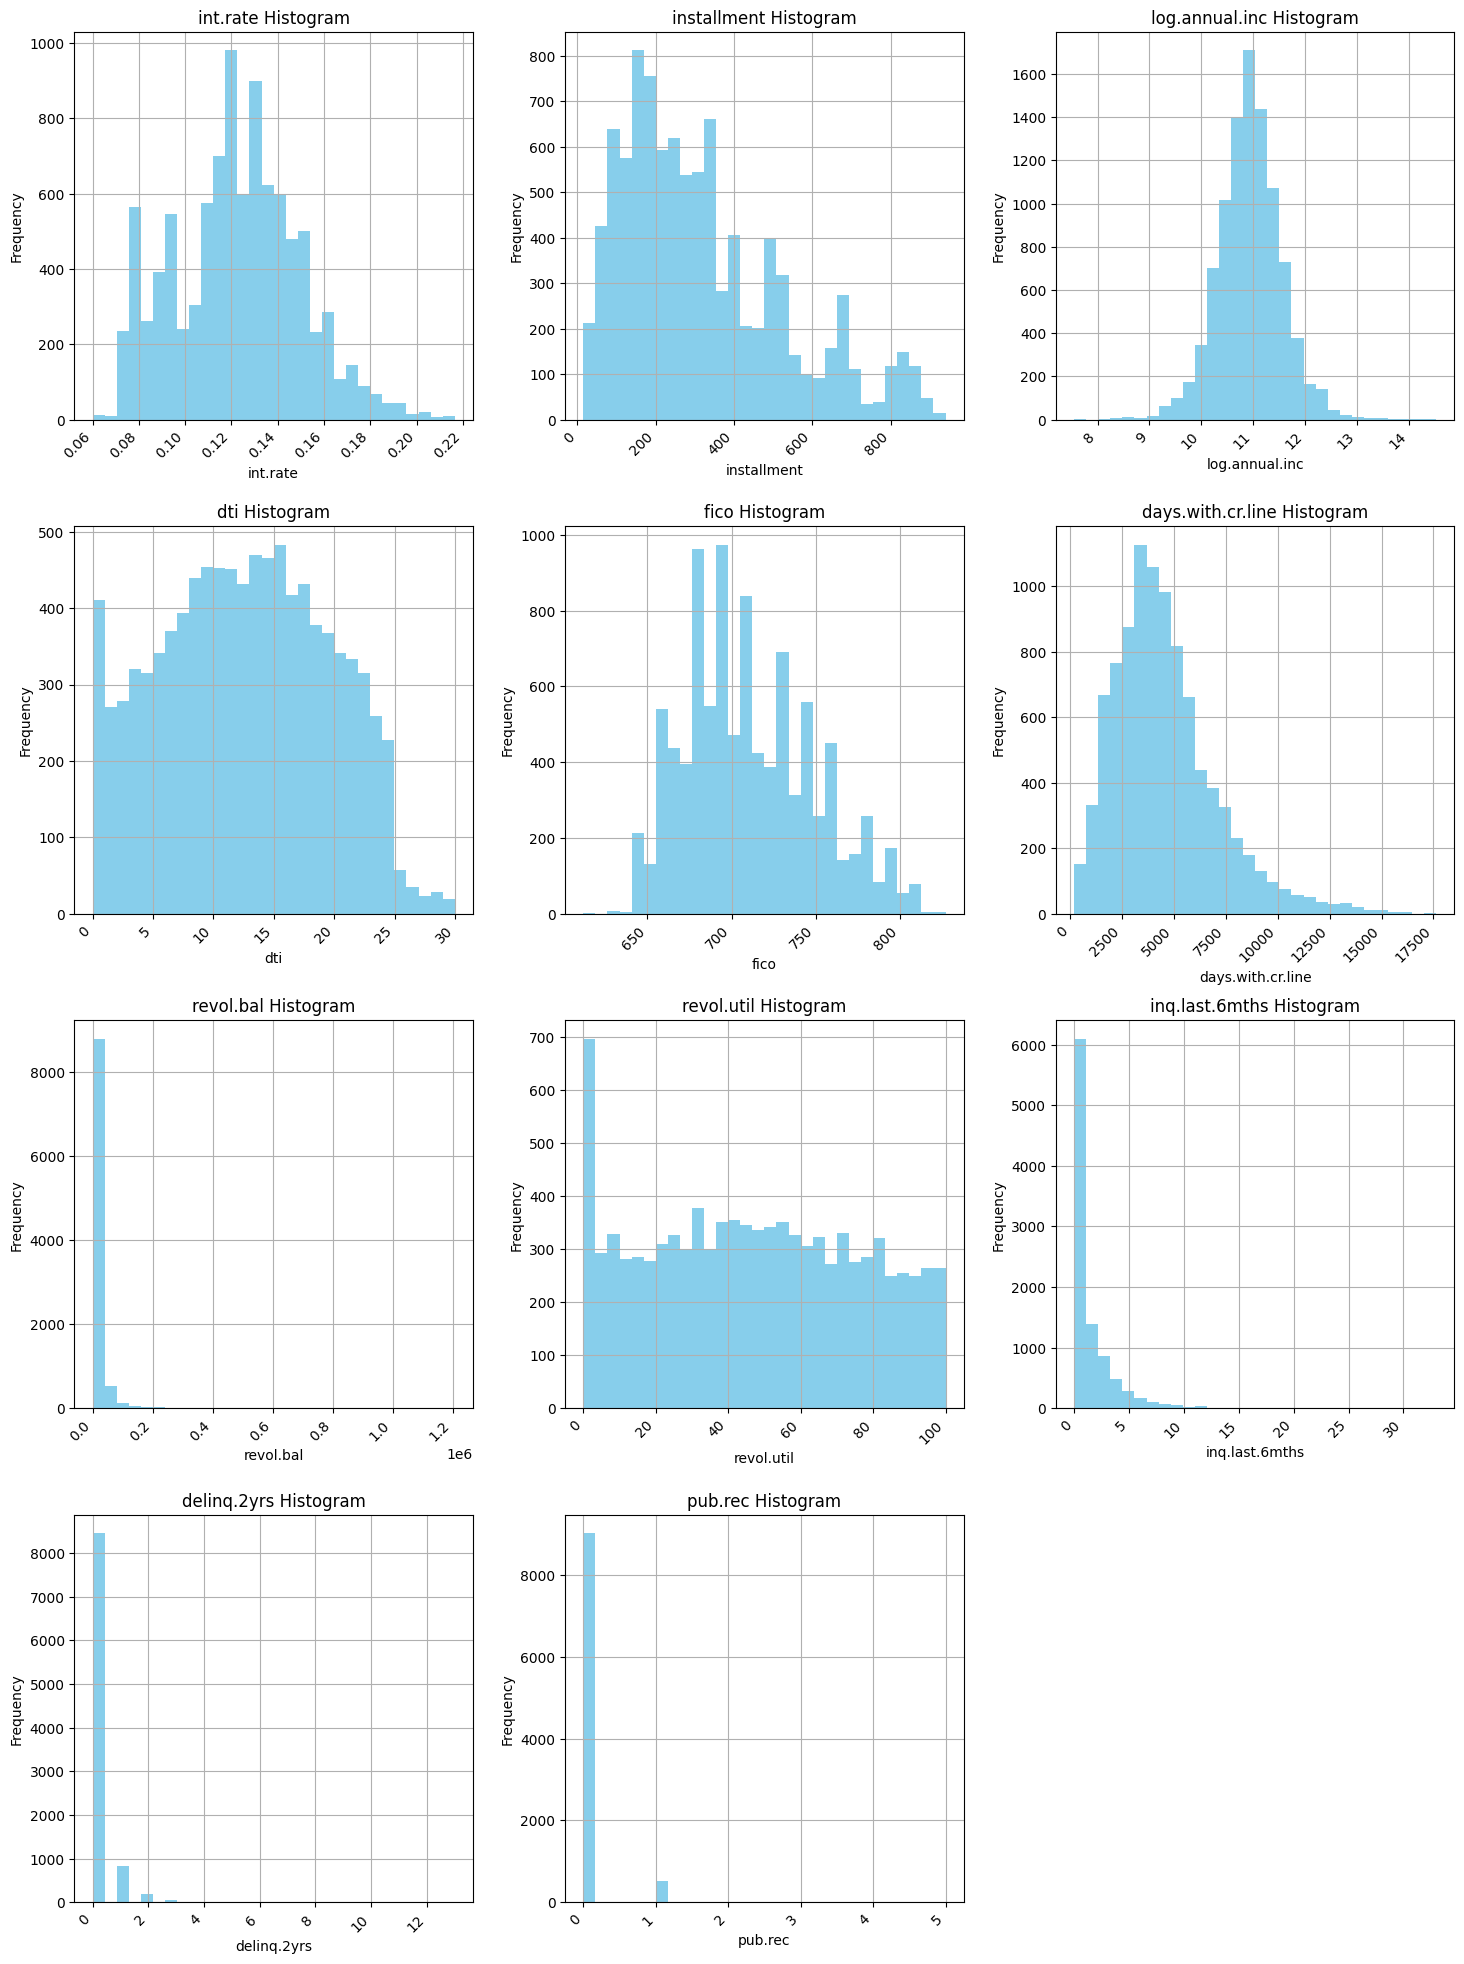

In [42]:
import matplotlib.pyplot as plt
import math

# Filter numerical features (int and float types)
numerical_features = df.select_dtypes(include=['int64', 'float64'])

# Calculate the number of rows and columns for subplots
num_features = len(numerical_features.columns)
num_cols = 3
num_rows = math.ceil(num_features / num_cols)

# Set figure size
plt.figure(figsize=(15, 5 * num_rows))

# Iterate over each numerical feature
for i, column in enumerate(numerical_features.columns, start=1):
    # Create subplot for each feature
    plt.subplot(num_rows, num_cols, i)
    
    # Plot histogram
    df[column].hist(color='skyblue', bins=30)
    
    # Add title and labels
    plt.title(f'{column} Histogram', fontsize=12)
    plt.xlabel(column, fontsize=10)
    plt.ylabel('Frequency', fontsize=10)
    
    # Rotate x-axis labels if necessary
    plt.xticks(rotation=45, ha='right')
    
# Adjust layout
plt.tight_layout(pad=2.0, h_pad=1.0)

# Show plot
plt.show()

### Logarithm Transformation of 'revol.bal' Feature

In this phase of the project, we applied a logarithm transformation to the 'revol.bal' feature in the dataset. Logarithm transformation is a common technique used to reduce the skewness of data distributions and make them more symmetric, which can improve the performance of certain machine learning algorithms and statistical analyses.

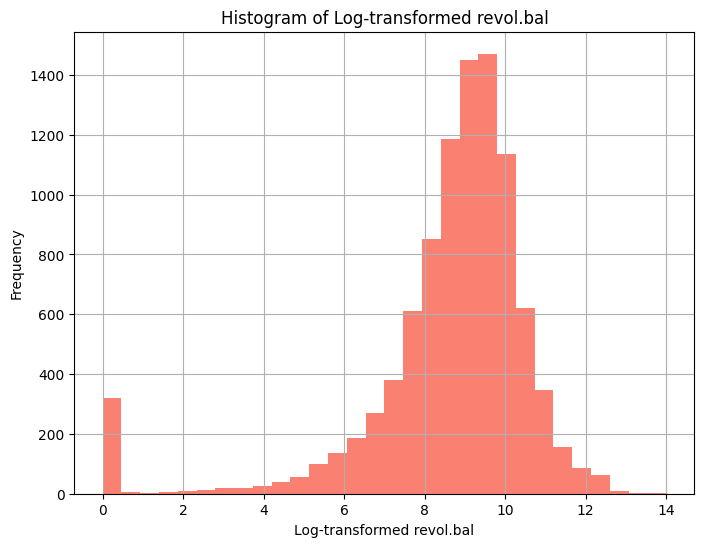

In [43]:
import numpy as np

# Apply logarithm transformation to 'revol.bal'
df['revol.bal_log'] = np.log1p(df['revol.bal'])

# Plot histogram of the transformed data
plt.figure(figsize=(8, 6))
df['revol.bal_log'].hist(color='salmon', bins=30)
plt.title('Histogram of Log-transformed revol.bal')
plt.xlabel('Log-transformed revol.bal')
plt.ylabel('Frequency')
plt.show()

### Correlation Matrix for Numerical Features

We generated a correlation matrix to examine the relationships between numerical features in the dataset.  
A correlation matrix provides valuable insights into the strength and direction of linear relationships between variables, helping identify potential patterns and dependencies.

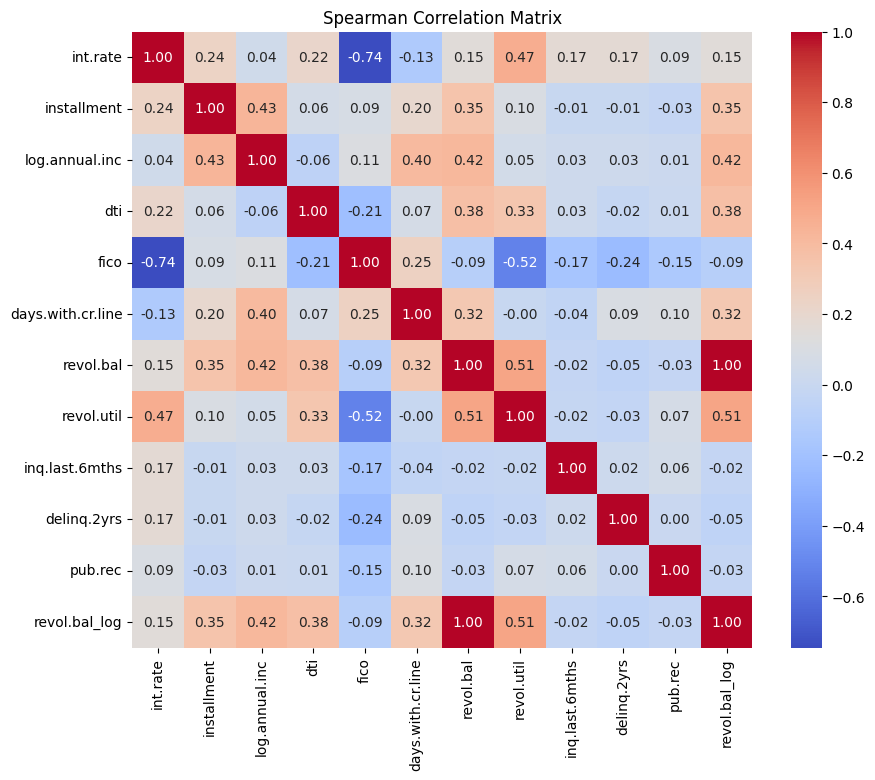

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter numerical features (int and float types)
numerical_features = df.select_dtypes(include=['int64', 'float64'])

# Calculate Spearman correlation matrix
spearman_corr_matrix = numerical_features.corr(method='spearman')

# Set figure size
plt.figure(figsize=(10, 8))

# Plot heatmap
sns.heatmap(spearman_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")

# Add title
plt.title('Spearman Correlation Matrix')

# Show plot
plt.show()

### Spearman Statistical Test for Correlations

We conducted the Spearman statistical test to evaluate correlations between numerical features in the dataset. The Spearman correlation coefficient measures the strength and direction of monotonic relationships between variables, making it suitable for assessing non-linear correlations and ordinal data.  
  
The result is displayed as a summary of higher correlations excludes correlations between a feature and itself, ensuring that only meaningful correlations are considered.

In [45]:
from scipy.stats import spearmanr

# Run Spearman correlation test
spearman_corr_test_results = {}

# Iterate over each pair of numerical features
for feature1 in numerical_features.columns:
    for feature2 in numerical_features.columns:
        if feature1 != feature2:  # Exclude correlations between a feature and itself
            # Run Spearman correlation test
            corr, p_value = spearmanr(numerical_features[feature1], numerical_features[feature2])
            spearman_corr_test_results[(feature1, feature2)] = (corr, p_value)

# Display Spearman correlation test results
print("Spearman Correlation Test Results:")
for (feature1, feature2), (corr, p_value) in spearman_corr_test_results.items():
    if abs(corr) > 0.5 and p_value < 0.05:  # Filter higher correlations
        print(f"{feature1} - {feature2}: Correlation = {corr:.3f}, p-value = {p_value:.3f}")

Spearman Correlation Test Results:
int.rate - fico: Correlation = -0.745, p-value = 0.000
fico - int.rate: Correlation = -0.745, p-value = 0.000
fico - revol.util: Correlation = -0.520, p-value = 0.000
revol.bal - revol.util: Correlation = 0.515, p-value = 0.000
revol.bal - revol.bal_log: Correlation = 1.000, p-value = 0.000
revol.util - fico: Correlation = -0.520, p-value = 0.000
revol.util - revol.bal: Correlation = 0.515, p-value = 0.000
revol.util - revol.bal_log: Correlation = 0.515, p-value = 0.000
revol.bal_log - revol.bal: Correlation = 1.000, p-value = 0.000
revol.bal_log - revol.util: Correlation = 0.515, p-value = 0.000


### Performing One-Hot Encoding on 'purpose'

In this phase of the project, we applied one-hot encoding to the 'purpose' feature in the dataset. One-hot encoding is a common technique used to transform categorical variables into binary format, where each category is represented by a binary vector with a single '1' indicating the presence of the category and '0's elsewhere.  
  
  One-hot encoding generates numerical features that are compatible with a wide range of machine learning algorithms, facilitating model training and evaluation.

In [46]:
# Perform one-hot encoding on 'purpose'
one_hot_encoded = pd.get_dummies(df['purpose'], prefix='purpose')

# Concatenate one-hot encoded columns with the original DataFrame
df = pd.concat([df, one_hot_encoded], axis=1)

# Drop the 'purpose' column from the DataFrame
df.drop('purpose', axis=1, inplace=True)

# Display the head of the DataFrame as a styled table
df_head_styled = df.head().style
df_head_styled

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,inq_bin,delinq_bin,pubrec_bin,revol.bal_log,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,True,0.118900,829.100000,11.350407,19.480000,737,5639.958333,28854,52.100000,0,0,0,False,bin1,bin1,bin1,10.270039,False,False,True,False,False,False,False
1,True,0.107100,228.220000,11.082143,14.290000,707,2760.000000,33623,76.700000,0,0,0,False,bin1,bin1,bin1,10.422995,False,True,False,False,False,False,False
2,True,0.135700,366.860000,10.373491,11.630000,682,4710.000000,3511,25.600000,1,0,0,False,bin2,bin1,bin1,8.163941,False,False,True,False,False,False,False
3,True,0.100800,162.340000,11.350407,8.100000,712,2699.958333,33667,73.200000,1,0,0,False,bin2,bin1,bin1,10.424303,False,False,True,False,False,False,False
4,True,0.142600,102.920000,11.299732,14.970000,667,4066.000000,4740,39.500000,0,1,0,False,bin1,bin2,bin1,8.464003,False,True,False,False,False,False,False


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   credit.policy               9578 non-null   bool   
 1   int.rate                    9578 non-null   float64
 2   installment                 9578 non-null   float64
 3   log.annual.inc              9578 non-null   float64
 4   dti                         9578 non-null   float64
 5   fico                        9578 non-null   int64  
 6   days.with.cr.line           9578 non-null   float64
 7   revol.bal                   9578 non-null   int64  
 8   revol.util                  9578 non-null   float64
 9   inq.last.6mths              9578 non-null   int64  
 10  delinq.2yrs                 9578 non-null   int64  
 11  pub.rec                     9578 non-null   int64  
 12  not.fully.paid              9578 non-null   bool   
 13  inq_bin                     9578 

### Dropping Features from DataFrame

We removed certain features from the DataFrame that were transformed or engineered into new features.

In [48]:
# List of features to drop
features_to_drop = ['revol.bal', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec']

# Drop the specified features from the DataFrame
df.drop(features_to_drop, axis=1, inplace=True)

# Display the head of the DataFrame as a styled table
df_head_styled = df.head().style
df_head_styled

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.util,not.fully.paid,inq_bin,delinq_bin,pubrec_bin,revol.bal_log,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,True,0.118900,829.100000,11.350407,19.480000,737,5639.958333,52.100000,False,bin1,bin1,bin1,10.270039,False,False,True,False,False,False,False
1,True,0.107100,228.220000,11.082143,14.290000,707,2760.000000,76.700000,False,bin1,bin1,bin1,10.422995,False,True,False,False,False,False,False
2,True,0.135700,366.860000,10.373491,11.630000,682,4710.000000,25.600000,False,bin2,bin1,bin1,8.163941,False,False,True,False,False,False,False
3,True,0.100800,162.340000,11.350407,8.100000,712,2699.958333,73.200000,False,bin2,bin1,bin1,10.424303,False,False,True,False,False,False,False
4,True,0.142600,102.920000,11.299732,14.970000,667,4066.000000,39.500000,False,bin1,bin2,bin1,8.464003,False,True,False,False,False,False,False


### Encoding Bins with Label Encoder

In this phase of the project, we employed label encoding to transform categorical 'bin's into numerical representations. Label encoding is a preprocessing technique commonly used to convert categorical variables into numerical format, which is required by many machine learning algorithms.

#### Purpose of Label Encoding

- **Numerical Representation**: Label encoding converts categorical variables into numerical format, allowing machine learning algorithms to process them more effectively.
- **Ordinal Encoding**: Label encoding is suitable for categorical variables with an inherent order or hierarchy, such as ordinal variables represented by bins.
- **Compatibility with Algorithms**: Many machine learning algorithms require numerical input, making label encoding a necessary preprocessing step for categorical features.

In [49]:
from sklearn.preprocessing import LabelEncoder

# List of binned categorical features to label encode
binned_categorical_features = ['inq_bin', 'delinq_bin', 'pubrec_bin']

# Updated feature names
updated_binned_categorical_features = ['inq.last.6mths_bin', 'delinq.2yrs_bin', 'pub.rec_bin']

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Apply label encoding to each binned categorical feature
for feature, updated_feature_name in zip(binned_categorical_features, updated_binned_categorical_features):
    df[updated_feature_name] = label_encoder.fit_transform(df[feature])
    df.drop(feature, axis=1, inplace=True)  # Drop the original feature

# Display the head of the DataFrame as a styled table
df_head_styled = df.head().style
df_head_styled

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.util,not.fully.paid,revol.bal_log,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business,inq.last.6mths_bin,delinq.2yrs_bin,pub.rec_bin
0,True,0.118900,829.100000,11.350407,19.480000,737,5639.958333,52.100000,False,10.270039,False,False,True,False,False,False,False,0,0,0
1,True,0.107100,228.220000,11.082143,14.290000,707,2760.000000,76.700000,False,10.422995,False,True,False,False,False,False,False,0,0,0
2,True,0.135700,366.860000,10.373491,11.630000,682,4710.000000,25.600000,False,8.163941,False,False,True,False,False,False,False,1,0,0
3,True,0.100800,162.340000,11.350407,8.100000,712,2699.958333,73.200000,False,10.424303,False,False,True,False,False,False,False,1,0,0
4,True,0.142600,102.920000,11.299732,14.970000,667,4066.000000,39.500000,False,8.464003,False,True,False,False,False,False,False,0,1,0


### Data Splitting

We split the dataset into training and testing sets to facilitate model training and evaluation. Data splitting is a critical step in machine learning projects, ensuring that models are trained on one subset of the data and evaluated on another subset to assess their generalization performance.

#### Purpose of Data Splitting

- **Model Training**: The training set is used to train the machine learning models, allowing them to learn patterns and relationships from the data.
- **Model Evaluation**: The testing set serves as an independent dataset to evaluate the models' performance on unseen data, providing insights into their ability to generalize to new observations.
- **Preventing Data Leakage**: Splitting the data helps prevent data leakage, where information from the testing set inadvertently influences model training, leading to overly optimistic performance estimates.

In [50]:
from sklearn.model_selection import train_test_split

# Split the data into features (X) and target variable (y)
X = df.drop('not.fully.paid', axis=1)  # Features
y = df['not.fully.paid']  # Target variable

# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the shape of the train and test sets
print("Train set shape:", X_train.shape, y_train.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Train set shape: (7662, 19) (7662,)
Test set shape: (1916, 19) (1916,)


### Normalization of Numerical Features

We applied normalization to the numerical features in the dataset. Normalization is a preprocessing technique used to scale numerical features to a similar range, typically between 0 and 1 or -1 and 1. We applied normalization to ensure that all features contribute equally to the model training process and prevent features with larger magnitudes from dominating those with smaller magnitudes.  
  
  It is a crucial preprocessing step in machine learning projects.


#### Steps for Normalization

1. **Data Splitting**: We split the dataset into training and testing sets to prevent data leakage and ensure that normalization is applied independently to each set.
2. **Numerical Feature Selection**: We identified the numerical features in the dataset that required normalization, typically those with varying scales and magnitudes.
3. **Normalization**: We applied normalization to the selected numerical features using techniques such as Min-Max Scaling or Z-score Standardization.
4. **Training and Testing**: We trained the machine learning models on the normalized training set and evaluated their performance on the normalized testing set.

In [51]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Select numerical features for normalization
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

# Initialize StandardScaler
scaler = StandardScaler()

# Fit the scaler to the training data and transform the numerical features
X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])

# Transform the numerical features in the test set using the scaler fitted on the training set
X_test[numerical_features] = scaler.transform(X_test[numerical_features])

# Display the head of the normalized training and testing sets as styled tables
print("Normalized Training Set:")
display(X_train.head().style)
print("\nNormalized Testing Set:")
display(X_test.head().style)

Normalized Training Set:


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.util,revol.bal_log,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business,inq.last.6mths_bin,delinq.2yrs_bin,pub.rec_bin
7317,True,0.868707,0.049122,-1.535031,-0.172101,-0.498260,0.268636,-0.608260,-1.633740,False,False,False,False,False,True,False,0.122044,-0.343875,-0.249202
350,True,-1.431963,-0.391757,0.475451,-0.948919,0.811133,-0.566438,-0.208505,-0.099480,False,True,False,False,False,False,False,-1.043916,-0.343875,-0.249202
5206,True,-0.283480,-0.865503,0.385937,-0.837116,0.156437,-0.302347,0.883928,0.365895,False,False,True,False,False,False,False,0.122044,-0.343875,-0.249202
2673,True,-1.083713,1.015832,0.203709,-0.616412,0.549255,-0.194484,1.335376,0.933546,True,False,False,False,False,False,False,-1.043916,-0.343875,-0.249202
3528,True,-0.364985,-0.024503,-0.393163,0.935774,1.203951,0.992200,-1.438785,-1.251671,False,False,False,False,False,True,False,0.122044,-0.343875,-0.249202



Normalized Testing Set:


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.util,revol.bal_log,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business,inq.last.6mths_bin,delinq.2yrs_bin,pub.rec_bin
8558,False,1.187319,0.659518,-0.551198,0.279471,-1.414835,-0.302347,1.231991,0.213059,False,False,True,False,False,False,False,1.288004,-0.343875,-0.249202
4629,True,-0.153813,1.046473,0.362771,-0.247604,0.549255,-0.386254,-0.191274,0.495554,False,False,True,False,False,False,False,1.288004,-0.343875,-0.249202
1383,True,-0.290890,-0.578554,-0.956987,0.164763,-0.498260,-0.997593,1.356053,0.441664,False,True,False,False,False,False,False,-1.043916,-0.343875,-0.249202
8142,False,1.561502,-1.021902,0.111011,2.259996,-1.022017,0.764486,-0.711645,0.174401,True,False,False,False,False,False,False,1.288004,1.967329,-0.249202
1768,True,-0.013031,-0.761673,0.315524,-1.249483,-0.236381,0.189107,-1.352631,-1.101934,True,False,False,False,False,False,False,0.122044,1.967329,-0.249202


# 4. Modeling and 5. Evaluation  

### Initial Model Training and Selection

In the initial phase of modeling, we trained three machine learning models to predict loan repayment status based on the dataset's features. The models selected for training were Random Forest Classifier, XGBoost Classifier, and Logistic Regression. Below are the reasons for choosing these models:

#### Model Selection Criteria

1. **Random Forest Classifier**:
   - Ensemble Method: Random Forests are ensemble learning methods that combine multiple decision trees to improve predictive performance and reduce overfitting.
   - Robustness to Imbalanced Data: Random Forests can handle imbalanced datasets effectively, making them suitable for our task, which involves predicting loan repayment status in an imbalanced dataset.
   - Feature Importance: Random Forests provide insights into feature importance, allowing us to identify significant predictors of loan repayment.

2. **XGBoost Classifier**:
   - Gradient Boosting Algorithm: XGBoost is an implementation of gradient boosting, which is known for its high predictive accuracy and ability to handle complex datasets.
   - Scalability: XGBoost is highly scalable and can handle large datasets efficiently, making it suitable for our project with a considerable number of features.
   - Regularization: XGBoost includes regularization techniques to prevent overfitting, ensuring robust model performance.

3. **Logistic Regression**:
   - Interpretability: Logistic Regression provides interpretable results, allowing us to understand the relationship between features and the likelihood of loan repayment.
   - Baseline Model: Logistic Regression serves as a baseline model for comparison with more complex algorithms like Random Forest and XGBoost.
   - Computational Efficiency: Logistic Regression is computationally efficient and suitable for quick prototyping and initial model evaluation.

#### Model Training Process

1. **Data Splitting**: We split the dataset into training and testing sets to train the models on a portion of the data and evaluate their performance on unseen data.
2. **Feature Engineering**: We performed necessary preprocessing steps such as handling missing values, encoding categorical variables, and scaling numerical features.
3. **Model Training**: We trained each model on the training set using default hyperparameters to establish baseline performance.
4. **Evaluation**: After training, we evaluated the models' performance using evaluation metrics such as accuracy, ROC AUC score, and confusion matrix.

In summary, we chose Random Forest, XGBoost, and Logistic Regression models based on their suitability for the task, algorithm characteristics, and the need for model interpretability. These models provided a diverse set of approaches to predicting loan repayment status, allowing us to compare their performance and select the most suitable model for further refinement.


In [52]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import roc_auc_score

# Initialize the models
rf_classifier = RandomForestClassifier(random_state=42)
xgb_classifier = XGBClassifier(random_state=42)
logistic_regression = LogisticRegression(random_state=42)

# Train the models
rf_classifier.fit(X_train, y_train)
xgb_classifier.fit(X_train, y_train)
logistic_regression.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_classifier.predict(X_test)
xgb_predictions = xgb_classifier.predict(X_test)
logistic_predictions = logistic_regression.predict(X_test)

# Calculate ROC AUC score for each model
rf_roc_auc = roc_auc_score(y_test, rf_classifier.predict_proba(X_test)[:, 1])
xgb_roc_auc = roc_auc_score(y_test, xgb_classifier.predict_proba(X_test)[:, 1])
logistic_roc_auc = roc_auc_score(y_test, logistic_regression.predict_proba(X_test)[:, 1])

# Evaluate model performance
print("Random Forest Classifier:")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Classification Report:")
print(classification_report(y_test, rf_predictions))
print("Random Forest Classifier ROC AUC Score:", rf_roc_auc)
print("-----------------------------")
print("\nXGBoost Classifier:")
print("Accuracy:", accuracy_score(y_test, xgb_predictions))
print("Classification Report:")
print(classification_report(y_test, xgb_predictions))
print("XGBoost Classifier ROC AUC Score:", xgb_roc_auc)
print("-----------------------------")
print("\nLogistic Regression:")
print("Accuracy:", accuracy_score(y_test, logistic_predictions))
print("Classification Report:")
print(classification_report(y_test, logistic_predictions))
print("Logistic Regression ROC AUC Score:", logistic_roc_auc)

Random Forest Classifier:
Accuracy: 0.8402922755741128
Classification Report:
              precision    recall  f1-score   support

       False       0.84      1.00      0.91      1611
        True       0.46      0.02      0.04       305

    accuracy                           0.84      1916
   macro avg       0.65      0.51      0.48      1916
weighted avg       0.78      0.84      0.77      1916

Random Forest Classifier ROC AUC Score: 0.6781939738071252
-----------------------------

XGBoost Classifier:
Accuracy: 0.8298538622129437
Classification Report:
              precision    recall  f1-score   support

       False       0.85      0.97      0.91      1611
        True       0.37      0.10      0.16       305

    accuracy                           0.83      1916
   macro avg       0.61      0.53      0.53      1916
weighted avg       0.77      0.83      0.79      1916

XGBoost Classifier ROC AUC Score: 0.6356198675092347
-----------------------------

Logistic Regression:
A

### Confusion Matrices

We calculated the confusion matrices for each model on the test set during the initial evaluation phase.  
  
  The confusion matrices were visually represented using heatmap plots, where each cell corresponds to the count of true positive, false positive, true negative, and false negative predictions.  
  By analyzing the confusion matrices, we gained insights into the models' ability to correctly classify samples from both classes and any biases or weaknesses in their predictions.  
  Confusion matrices are particularly useful in scenarios with imbalanced class distributions, where accuracy alone may not provide an accurate representation of model performance.  
  They help identify specific types of errors made by the model, such as misclassifying minority class samples.

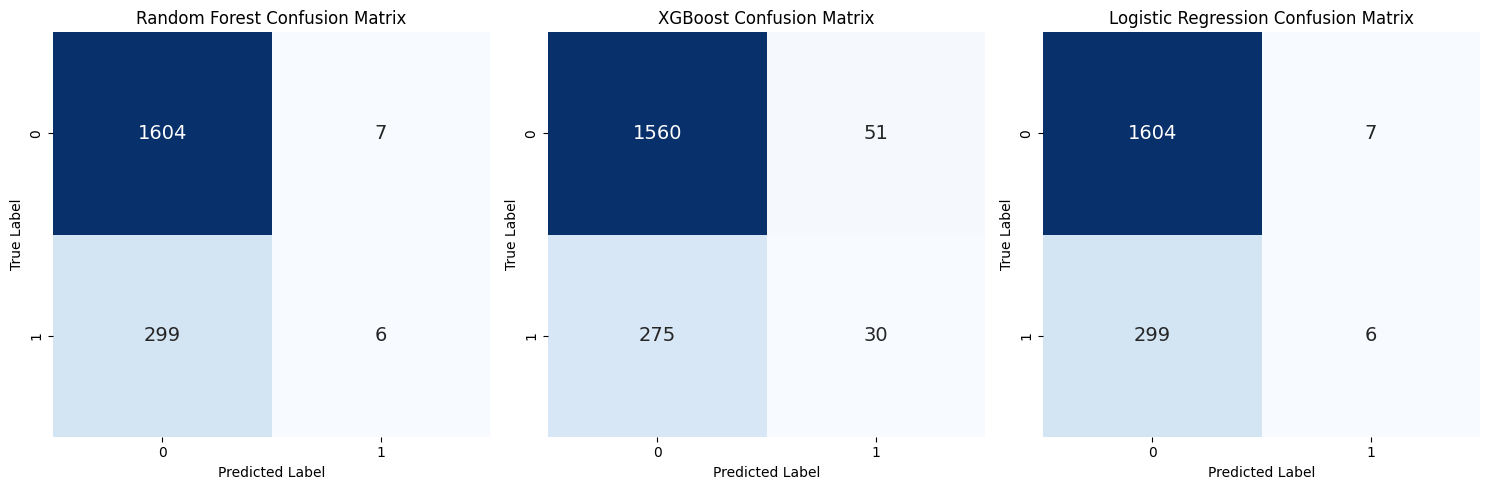

In [53]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix for each model
rf_conf_matrix = confusion_matrix(y_test, rf_predictions)
xgb_conf_matrix = confusion_matrix(y_test, xgb_predictions)
logistic_conf_matrix = confusion_matrix(y_test, logistic_predictions)

# Plot confusion matrix for each model
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.heatmap(rf_conf_matrix, annot=True, cmap='Blues', fmt='d', cbar=False, annot_kws={"size": 14})
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.subplot(1, 3, 2)
sns.heatmap(xgb_conf_matrix, annot=True, cmap='Blues', fmt='d', cbar=False, annot_kws={"size": 14})
plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.subplot(1, 3, 3)
sns.heatmap(logistic_conf_matrix, annot=True, cmap='Blues', fmt='d', cbar=False, annot_kws={"size": 14})
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.tight_layout()
plt.show()

### SMOTE (Synthetic Minority Over-sampling Technique)

In this phase of the project, we encountered a class imbalance issue where one class (fully repay) significantly outnumbered the other class (not fully repay) in the target variable. To address this imbalance and prevent the models from being biased towards the majority class, we employed the Synthetic Minority Over-sampling Technique (SMOTE), and then ran and reestimated all models.

#### Benefits of SMOTE

- **Improved Model Performance**: By balancing the class distribution, SMOTE helps prevent models from being biased towards the majority class, leading to more accurate predictions on the minority class.
- **Preserved Information**: SMOTE generates synthetic samples that closely resemble real instances, preserving the underlying information in the dataset.
- **Easy Implementation**: SMOTE is easy to implement using libraries such as imbalanced-learn in Python, making it accessible for practitioners working with imbalanced datasets.

In [54]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Perform oversampling on the training data
X_train_resampled_smote, y_train_resampled_smote = smote.fit_resample(X_train, y_train)

# Train the models on resampled data
rf_classifier_smote = RandomForestClassifier(random_state=42)
xgb_classifier_smote = XGBClassifier(random_state=42)
logistic_regression_smote = LogisticRegression(random_state=42)

rf_classifier_smote.fit(X_train_resampled_smote, y_train_resampled_smote)
xgb_classifier_smote.fit(X_train_resampled_smote, y_train_resampled_smote)
logistic_regression_smote.fit(X_train_resampled_smote, y_train_resampled_smote)

# Make predictions on the test set
rf_predictions_smote = rf_classifier_smote.predict(X_test)
xgb_predictions_smote = xgb_classifier_smote.predict(X_test)
logistic_predictions_smote = logistic_regression_smote.predict(X_test)

# Evaluate model performance
print("Random Forest Classifier:")
print("Accuracy:", accuracy_score(y_test, rf_predictions_smote))
print("ROC AUC Score:", roc_auc_score(y_test, rf_classifier_smote.predict_proba(X_test)[:, 1]))
print("Classification Report:")
print(classification_report(y_test, rf_predictions_smote))
print("-----------------------------")
print("\nXGBoost Classifier:")
print("Accuracy:", accuracy_score(y_test, xgb_predictions_smote))
print("ROC AUC Score:", roc_auc_score(y_test, xgb_classifier_smote.predict_proba(X_test)[:, 1]))
print("Classification Report:")
print(classification_report(y_test, xgb_predictions_smote))
print("-----------------------------")
print("\nLogistic Regression:")
print("Accuracy:", accuracy_score(y_test, logistic_predictions_smote))
print("ROC AUC Score:", roc_auc_score(y_test, logistic_regression_smote.predict_proba(X_test)[:, 1]))
print("Classification Report:")
print(classification_report(y_test, logistic_predictions_smote))

Random Forest Classifier:
Accuracy: 0.8094989561586639
ROC AUC Score: 0.6651748735639201
Classification Report:
              precision    recall  f1-score   support

       False       0.86      0.93      0.89      1611
        True       0.32      0.17      0.23       305

    accuracy                           0.81      1916
   macro avg       0.59      0.55      0.56      1916
weighted avg       0.77      0.81      0.79      1916

-----------------------------

XGBoost Classifier:
Accuracy: 0.8021920668058455
ROC AUC Score: 0.6289668366048988
Classification Report:
              precision    recall  f1-score   support

       False       0.85      0.93      0.89      1611
        True       0.28      0.15      0.20       305

    accuracy                           0.80      1916
   macro avg       0.56      0.54      0.54      1916
weighted avg       0.76      0.80      0.78      1916

-----------------------------

Logistic Regression:
Accuracy: 0.7134655532359081
ROC AUC Score: 0

and again **Confusion Matrices**

After applying the Synthetic Minority Over-sampling Technique (SMOTE) to address class imbalance in the dataset, we reevaluated the performance of our models using confusion matrices.

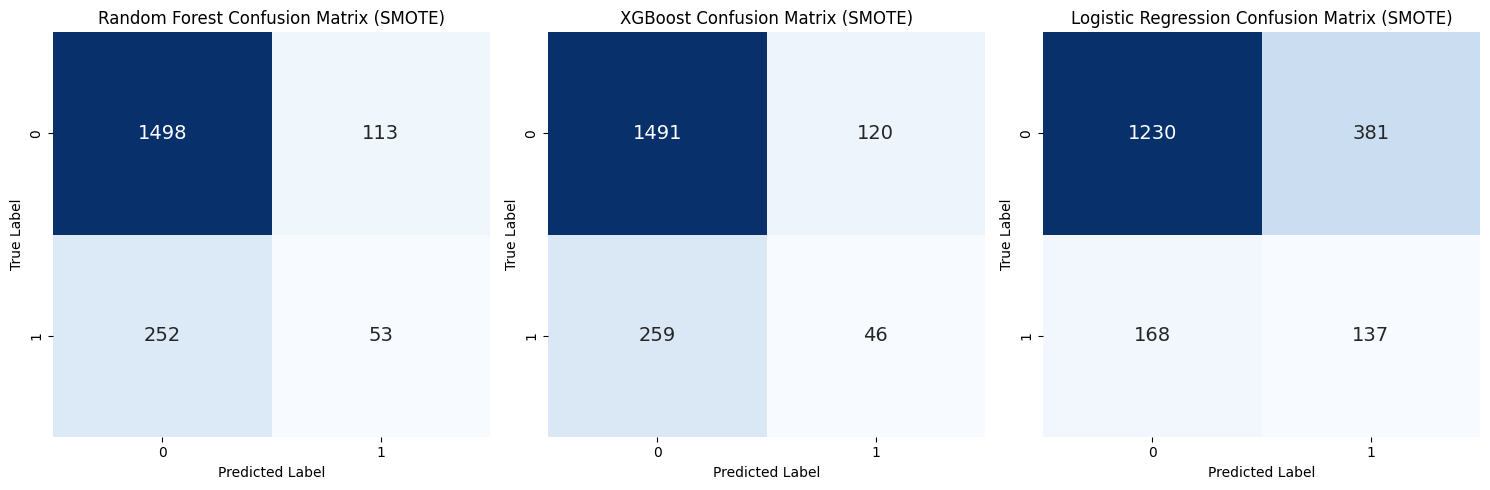

In [55]:
# Calculate confusion matrix for each model after SMOTE
rf_conf_matrix_smote = confusion_matrix(y_test, rf_predictions_smote)
xgb_conf_matrix_smote = confusion_matrix(y_test, xgb_predictions_smote)
logistic_conf_matrix_smote = confusion_matrix(y_test, logistic_predictions_smote)

# Plot confusion matrix for each model after SMOTE
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.heatmap(rf_conf_matrix_smote, annot=True, cmap='Blues', fmt='d', cbar=False, annot_kws={"size": 14})
plt.title('Random Forest Confusion Matrix (SMOTE)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.subplot(1, 3, 2)
sns.heatmap(xgb_conf_matrix_smote, annot=True, cmap='Blues', fmt='d', cbar=False, annot_kws={"size": 14})
plt.title('XGBoost Confusion Matrix (SMOTE)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.subplot(1, 3, 3)
sns.heatmap(logistic_conf_matrix_smote, annot=True, cmap='Blues', fmt='d', cbar=False, annot_kws={"size": 14})
plt.title('Logistic Regression Confusion Matrix (SMOTE)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.tight_layout()
plt.show()

# Conclusion  
In this project, we explored a dataset containing information about loan applicants and their repayment status. The primary objective was to build predictive models to determine whether a borrower will fully repay the loan or not, based on various features provided in the dataset. We followed a systematic approach, starting from data exploration and preprocessing to model training and evaluation.  

### Key Findings
* We performed extensive data preprocessing tasks, including handling missing values, encoding categorical variables, and scaling numerical features.
* Three machine learning models, namely Random Forest Classifier, XGBoost Classifier, and Logistic Regression, were trained and evaluated on the dataset.
* Initially, we evaluated the models without any oversampling technique and observed imbalanced class distributions.
* To address the class imbalance issue, we experimented with oversampling techniques such as RandomOverSampler and SMOTE.
* After applying oversampling using SMOTE, we retrained the models and evaluated their performance.
* Evaluation metrics such as accuracy, ROC AUC score, and confusion matrices were used to assess the models' performance.  

### Model Comparison
* Each model showed promising performance improvements after oversampling with SMOTE.
* The choice of the best model depends on the specific business goals and the importance of correctly predicting each class.
* It seems the Logistic Regression model demonstrated the highest ROC AUC score among the three models.
* However, it's essential to consider the business context and determine which class (fully repay or not) is more critical for achieving financial goals.  
  
### Next Steps
* In the next steps, we can further enhance the models' performance by conducting hyperparameter tuning using techniques like grid search or randomized search.
* Additionally, we can explore more advanced ensemble methods and deep learning models to potentially improve predictive accuracy.  
  
  
  Overall, this project provided valuable insights into the predictive modeling of loan repayment, highlighting the importance of considering class imbalance and selecting appropriate evaluation metrics for business-driven decision-making.